# Notebook 05 — Walk-Forward Validation

**Purpose:** This is the REAL test. Run proper time-series cross-validation across multiple periods.

Random splits and k-fold are invalid for financial time-series. This notebook implements the correct method:
- Train on 1 year → test on 3 months → slide forward 1 month → repeat
- 24-bar embargo gap between train and test (prevents label overlap leakage)

**This notebook gives you the definitive OOS accuracy number that matters.**

**Prerequisite:** `features/eurusd_labelled.csv` from Notebook 03.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

from src.features import FEATURE_COLS
from src.validation import walk_forward_validate, save_results
from src.models import build_lgbm_baseline

df = pd.read_csv('../features/eurusd_labelled.csv', index_col=0, parse_dates=True)
print(f"Loaded: {df.shape}")
print(f"Clean rows (no time-outs): {(df['label_raw'] != 0).sum():,}")
print(f"Date range: {df.index[0].date()} -> {df.index[-1].date()}")

Loaded: (31628, 30)
Clean rows (no time-outs): 31,628
Date range: 2020-01-03 -> 2026-05-28


## Step 1 — Configure and run walk-forward validation

This will take 2-5 minutes depending on how many folds your data supports.

**NOTE on row counts:** 1H bars per period:
- 1 year ≈ 2,520 bars (252 trading days × ~10 bars/day)
- 3 months ≈ 630 bars
- 1 month ≈ 210 bars

If your dataset has fewer than 4,000 clean rows, reduce train_bars to 1260 and test_bars to 420.

In [2]:
# Check how many rows we have and auto-adjust if needed
n_rows = len(df)
print(f"Total clean rows available: {n_rows:,}")

TRAIN_BARS = 2520   # ~1 year
TEST_BARS  = 630    # ~3 months
STEP_BARS  = 210    # ~1 month slide
EMBARGO    = 24     # 24H gap

min_needed = TRAIN_BARS + EMBARGO + TEST_BARS
if n_rows < min_needed:
    print(f"\n[WARNING] Not enough rows for default settings (need {min_needed}, have {n_rows})")
    TRAIN_BARS = max(500, int(n_rows * 0.55))
    TEST_BARS  = max(100, int(n_rows * 0.15))
    STEP_BARS  = max(50,  int(n_rows * 0.05))
    print(f"Auto-adjusted: train={TRAIN_BARS}, test={TEST_BARS}, step={STEP_BARS}")
else:
    print(f"Dataset is large enough. Using default walk-forward parameters.")

expected_folds = max(0, (n_rows - TRAIN_BARS - EMBARGO - TEST_BARS) // STEP_BARS + 1)
print(f"Expected number of folds: ~{expected_folds}")

Total clean rows available: 31,628
Dataset is large enough. Using default walk-forward parameters.
Expected number of folds: ~136


In [3]:
results_df = walk_forward_validate(
    df            = df,
    feature_cols  = FEATURE_COLS,
    label_col     = 'label_binary',
    train_bars    = TRAIN_BARS,
    test_bars     = TEST_BARS,
    step_bars     = STEP_BARS,
    embargo_bars  = EMBARGO,
    confidence_thresh = 0.60,
    model_builder = build_lgbm_baseline,
)

  Walk-forward validation
  Train: 2520 bars | Test: 630 bars | Step: 210 bars | Embargo: 24 bars
  Fold 01 | 2020-07-10 → 2020-08-26 | acc=0.598 | hc_acc=0.614 | n=630
  Fold 02 | 2020-07-27 → 2020-09-10 | acc=0.646 | hc_acc=0.666 | n=630
  Fold 03 | 2020-08-10 → 2020-09-24 | acc=0.637 | hc_acc=0.678 | n=630
  Fold 04 | 2020-08-26 → 2020-10-12 | acc=0.692 | hc_acc=0.732 | n=630
  Fold 05 | 2020-09-10 → 2020-10-27 | acc=0.705 | hc_acc=0.716 | n=630
  Fold 06 | 2020-09-24 → 2020-11-12 | acc=0.678 | hc_acc=0.714 | n=630
  Fold 07 | 2020-10-12 → 2020-11-27 | acc=0.643 | hc_acc=0.649 | n=630
  Fold 08 | 2020-10-27 → 2020-12-11 | acc=0.649 | hc_acc=0.679 | n=630
  Fold 09 | 2020-11-13 → 2020-12-28 | acc=0.616 | hc_acc=0.643 | n=630
  Fold 10 | 2020-11-27 → 2021-01-12 | acc=0.671 | hc_acc=0.740 | n=630
  Fold 11 | 2020-12-11 → 2021-01-28 | acc=0.676 | hc_acc=0.754 | n=630
  Fold 12 | 2020-12-28 → 2021-02-11 | acc=0.698 | hc_acc=0.789 | n=630
  Fold 13 | 2021-01-12 → 2021-02-25 | acc=0.670 | 

## Step 2 — Per-fold results table

In [4]:
print("\nPer-fold detail:")
display_cols = ['fold','test_start','test_end','n_train','n_test','accuracy','hc_accuracy','profit_factor']
available_cols = [c for c in display_cols if c in results_df.columns]
print(results_df[available_cols].to_string(index=False))


Per-fold detail:
 fold test_start   test_end  n_train  n_test  accuracy  hc_accuracy  profit_factor
    1 2020-07-10 2020-08-26     2520     630    0.5984       0.6142          2.235
    2 2020-07-27 2020-09-10     2520     630    0.6460       0.6657          2.738
    3 2020-08-10 2020-09-24     2520     630    0.6365       0.6779          2.627
    4 2020-08-26 2020-10-12     2520     630    0.6921       0.7324          3.371
    5 2020-09-10 2020-10-27     2520     630    0.7048       0.7161          3.581
    6 2020-09-24 2020-11-12     2520     630    0.6778       0.7139          3.155
    7 2020-10-12 2020-11-27     2520     630    0.6429       0.6492          2.700
    8 2020-10-27 2020-12-11     2520     630    0.6492       0.6786          2.776
    9 2020-11-13 2020-12-28     2520     630    0.6159       0.6427          2.405
   10 2020-11-27 2021-01-12     2520     630    0.6714       0.7402          3.065
   11 2020-12-11 2021-01-28     2520     630    0.6762       0.7542  

## Step 3 — Accuracy over time chart

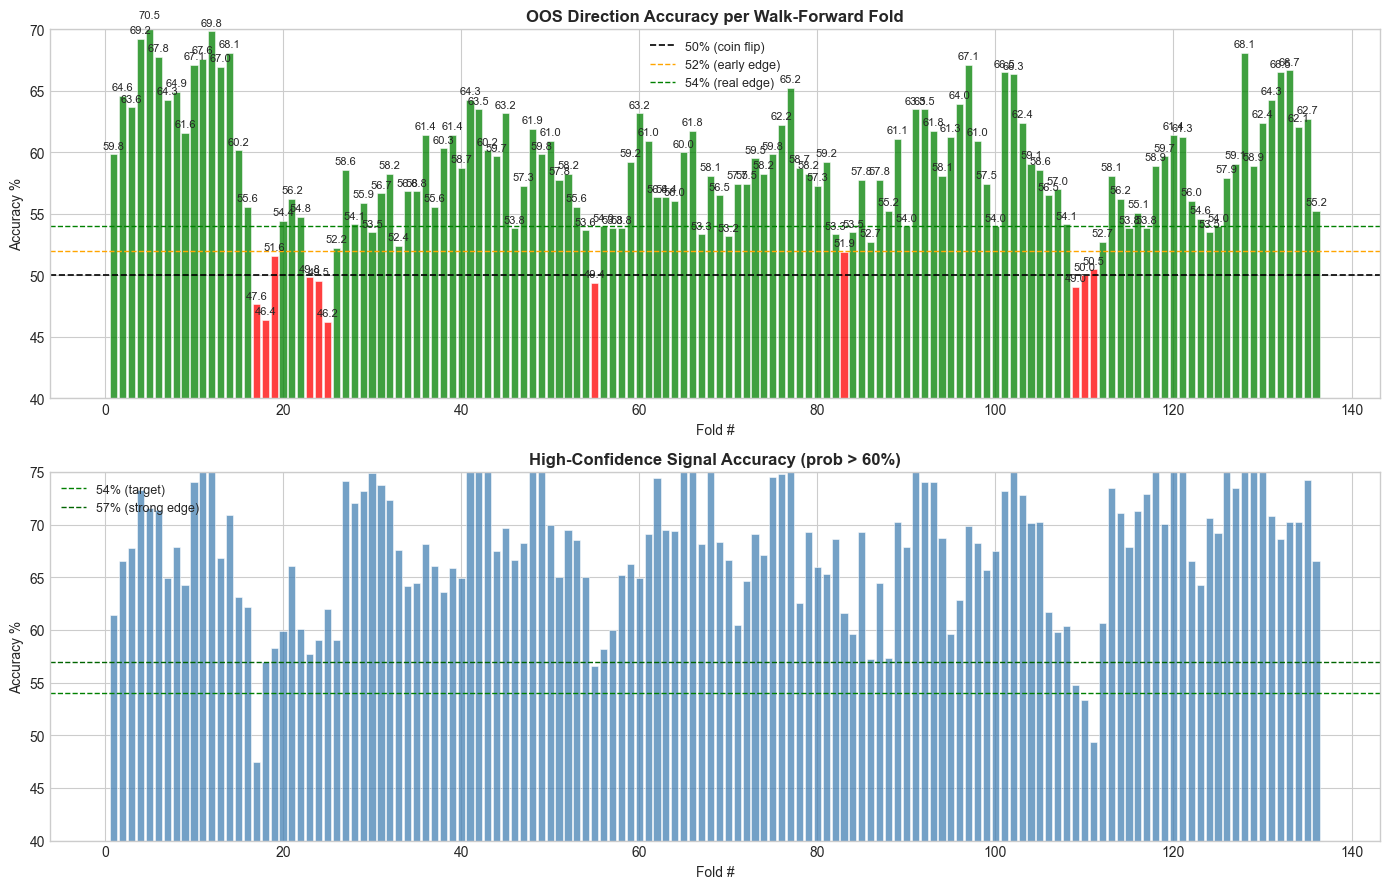

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Top: per-fold accuracy
fold_nums = results_df['fold']
accs = results_df['accuracy'] * 100

axes[0].bar(fold_nums, accs, color=['green' if a > 52 else 'red' for a in accs],
            alpha=0.75, edgecolor='white', linewidth=0.5)
axes[0].axhline(50, color='black', linestyle='--', linewidth=1.2, label='50% (coin flip)')
axes[0].axhline(52, color='orange', linestyle='--', linewidth=1.0, label='52% (early edge)')
axes[0].axhline(54, color='green', linestyle='--', linewidth=1.0, label='54% (real edge)')
axes[0].set_title('OOS Direction Accuracy per Walk-Forward Fold', fontweight='bold')
axes[0].set_xlabel('Fold #')
axes[0].set_ylabel('Accuracy %')
axes[0].set_ylim(40, 70)
axes[0].legend(fontsize=9)
for i, (f, a) in enumerate(zip(fold_nums, accs)):
    axes[0].text(f, a + 0.3, f'{a:.1f}', ha='center', va='bottom', fontsize=8)

# Bottom: high-confidence accuracy
hc = results_df['hc_accuracy'].dropna() * 100
hc_folds = results_df.loc[results_df['hc_accuracy'].notna(), 'fold']
if len(hc) > 0:
    axes[1].bar(hc_folds, hc, color='steelblue', alpha=0.75, edgecolor='white', linewidth=0.5)
    axes[1].axhline(54, color='green', linestyle='--', linewidth=1.0, label='54% (target)')
    axes[1].axhline(57, color='darkgreen', linestyle='--', linewidth=1.0, label='57% (strong edge)')
    axes[1].set_title('High-Confidence Signal Accuracy (prob > 60%)', fontweight='bold')
    axes[1].set_xlabel('Fold #')
    axes[1].set_ylabel('Accuracy %')
    axes[1].set_ylim(40, 75)
    axes[1].legend(fontsize=9)
else:
    axes[1].text(0.5, 0.5, 'No high-confidence signals in any fold\n(confidence threshold may be too strict)',
                 ha='center', va='center', transform=axes[1].transAxes, fontsize=11)

plt.tight_layout()
plt.savefig('../results/05_walk_forward_accuracy.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 4 — Stability analysis

In [6]:
print("Walk-forward stability report:")
print("-" * 45)
print(f"  Mean OOS accuracy : {results_df['accuracy'].mean()*100:.2f}%")
print(f"  Std               : {results_df['accuracy'].std()*100:.2f}%")
print(f"  Min (worst fold)  : {results_df['accuracy'].min()*100:.2f}%")
print(f"  Max (best fold)   : {results_df['accuracy'].max()*100:.2f}%")
print(f"  Folds > 52%       : {(results_df['accuracy'] > 0.52).sum()} / {len(results_df)}")
print(f"  Folds > 54%       : {(results_df['accuracy'] > 0.54).sum()} / {len(results_df)}")
print()
print("Consistency score (lower std = more consistent):")
cv = results_df['accuracy'].std() / results_df['accuracy'].mean()
if cv < 0.03:
    print(f"  CV = {cv:.3f} — CONSISTENT model (good)")
elif cv < 0.06:
    print(f"  CV = {cv:.3f} — MODERATE variance (acceptable)")
else:
    print(f"  CV = {cv:.3f} — HIGH variance (model is regime-sensitive)")
    print("  Action: Add regime features to help model identify its own edge conditions.")

Walk-forward stability report:
---------------------------------------------
  Mean OOS accuracy : 58.47%
  Std               : 5.11%
  Min (worst fold)  : 46.19%
  Max (best fold)   : 70.48%
  Folds > 52%       : 125 / 136
  Folds > 54%       : 105 / 136

Consistency score (lower std = more consistent):
  CV = 0.087 — HIGH variance (model is regime-sensitive)
  Action: Add regime features to help model identify its own edge conditions.


## Step 5 — Save results

In [7]:
save_results(results_df, 'walk_forward_results.csv')
print("\nAll fold results saved to results/walk_forward_results.csv")

  [SAVED] Results saved to: C:\Users\omtej\Projects\2020_algo_based\results\walk_forward_results.csv

All fold results saved to results/walk_forward_results.csv


In [8]:
results = pd.read_csv('../results/walk_forward_results.csv')
bad_folds = results[results['accuracy'] < 0.50].sort_values('accuracy')
print("Folds below 50% accuracy:")
print(bad_folds[['fold','test_start','test_end','accuracy','long_pct']].to_string())

Folds below 50% accuracy:
     fold  test_start    test_end  accuracy  long_pct
24     25  2021-07-16  2021-09-03    0.4619     0.405
17     18  2021-03-29  2021-05-13    0.4635     0.403
16     17  2021-03-12  2021-04-27    0.4762     0.367
108   109  2025-02-20  2025-04-08    0.4905     0.430
54     55  2022-10-20  2022-12-06    0.4937     0.443
23     24  2021-06-30  2021-08-19    0.4952     0.368
22     23  2021-06-15  2021-08-03    0.4984     0.400


## ✅ Checkpoint — Walk-Forward Interpretation Guide

### Mean OOS accuracy decision tree:

| Mean accuracy | Diagnosis | Next action |
|---|---|---|
| < 50% | Pipeline bug | Fix shift(+1) and label construction |
| 50–52% | Clean baseline, no edge | Add 4H/Daily macro context features |
| 52–54% | Early edge | Add XGBoost as second model |
| 54–57% | Real edge | Add regime-gated routing |
| > 57% | Strong signal | Verify no leakage, then add meta-learner |

### Key things to note:
- **Consistency matters more than peak accuracy.** A model with 53% ± 1% is better than 57% ± 8%.
- **Worst fold tells you the downside.** If the worst fold is below 48%, the model fails in certain regimes.
- **High-confidence accuracy should be higher than all-signals accuracy.** If they're the same, the confidence scores are not calibrated.

**→ Open `06_shap_analysis.ipynb` next — required before making any model changes.**